## Wstęp do Uczenia Maszynowego

#### Laboratorium 02


### Zakres laboratorium

- drzewa decyzyjne w regresji i klasyfikacji
- kryteria podziału oraz złożoność drzewa
- macierz pomyłek i podstawowe metryki klasyfikacji


In [1]:
# Import potrzebnych pakietów
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score


### 0. Drzewa decyzyjne - regresja

Na chwilę wrócimy do zajęć lab 01.

Pracowaliśmy ostatnio nad zadaniem regresji i przewidywaniem wynagrodzenia dla zawodników baseballu.

Stworzyliśmy pierwszy model i ocenialiśmy jego jakość mierząc błąd średniokwadratowy.

In [2]:
## Kod pobierający dane
Hitters = pd.read_csv("https://raw.githubusercontent.com/kozaka93/2026Z-MachineLearning/refs/heads/main/labs/lab01/Hitters.csv", index_col =[0])

## Ograniczamy zbiór do trzech zmiennych
Hitters_small = Hitters[["Years", "Hits", "Salary"]]

## Usuwamy braki danych
Hitters_small = Hitters_small.dropna()

## Dzielimy zbiór danych na y (zmienną docelową) i X (zmienne wejściowe)
y = Hitters_small.Salary
X = Hitters_small.drop(["Salary"], axis=1) 

# Podział na zbiór treningowy (do uczenia) i testowy (do końcowej oceny)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=123
)

# Wydzielenie zbioru walidacyjnego ze zbioru treningowego
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=456
)

## Budujemy drzewo z 3 liśćmi (regresja).
Tree3 = tree.DecisionTreeRegressor(max_leaf_nodes=3, random_state=123)
Tree3 = Tree3.fit(X_train, y_train)

<img src="X_train_val_test.png" alt="drawing" width="600"/>

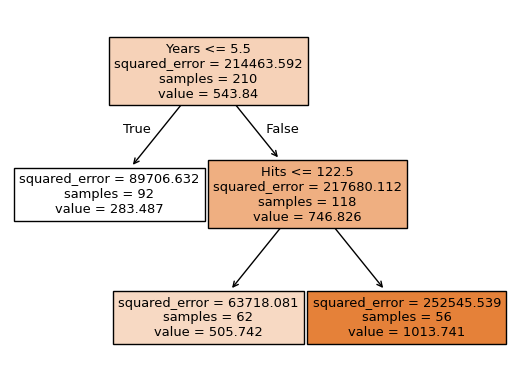

In [3]:
## Rysunek drzewa
tree.plot_tree(Tree3, 
               feature_names=Tree3.feature_names_in_.tolist(),
               filled=True)
plt.show()

### Regiony 

<img src="Five-Region-Examples.png" width="400"/>

###### Źródło:  James, G., Witten, D., Hastie, T., Tibshirani, R., Taylor, J. (2023). An Introduction to Statistical Learning with Applications in Python, Springer Science+Business Media, New York. https://www.statlearning.com/

-----
##### *Zadanie 1*
Na podstawie informacji o utworzonym drzewie zdefiniuj regiony $R_1$, $R_2$ i $R_3$.

In [4]:
Hitters_small.describe()

,Years,Hits,Salary
count,263.000000,263.000000,263.000000
mean,7.311787,107.828897,535.925882
std,4.793616,45.125326,451.118681
min,1.000000,1.000000,67.500000
25%,4.000000,71.500000,190.000000
50%,6.000000,103.000000,425.000000
75%,10.000000,141.500000,750.000000
max,24.000000,238.000000,2460.000000


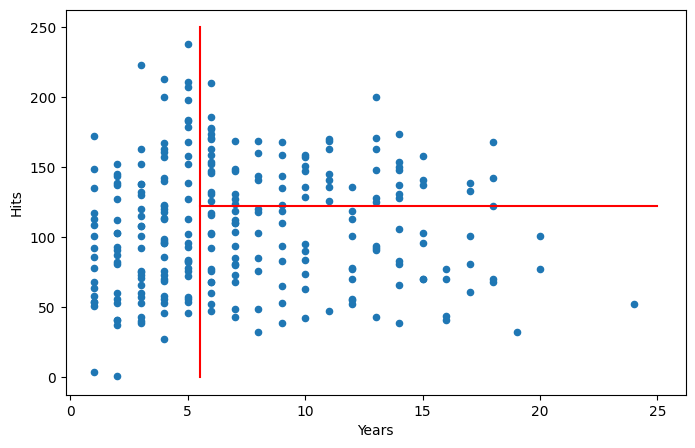

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8,5))
Hitters_small.plot(x='Years', y='Hits', kind='scatter', ax=ax)
ax.plot(np.repeat(5.5, 2), np.array([0, 250]), color="red")
ax.plot(np.array([5.5, 25]), np.repeat(122.5, 2), color="red")

-----
##### *Zadanie 2*
Na bazie przedstawionych poniżej regionów narysuj odpowiadające im drzewo decyzyjne.

<img src="Regions_Task.png" alt="drawing" width="400"/>

#### Jak konstruować regiony w przypadku drzewa dla zadania regresji?
**Cel**: Znaleźć $R_1, R_2, \dots, R_J$, które minimalizują $RSS$.

$$RSS = \sum_{j = 1}^{J} \sum_{i \in R_j}^{}(y_i - \hat{y}_{R_j})^2$$

Niestety nie jesteśmy w stanie rozpatrzeć wszystkich możliwości - zbyt złożone obliczeniowo.

Używamy podejścia *top-down, greedy*:
- *top-down* — zaczynamy od wszystkich obserwacji w jednym regionie, a następnie w kolejnych krokach dzielimy go na mniejsze regiony
- *greedy* - na każdym etapie procesu budowania drzewa dokonywany jest najlepszy podział, nie patrzymy w przyszłość

Proces powtarzamy do momentu spełnienia kryterium stopu, np. w liściu nie może być mniej niż 5 obserwacji.


Zadanie polega na wzięciu predyktora $X_j$ i szukaniu punktu przecięcia $s$

$$\{X |X_j < s\}  \ \ \{X | X_j \geq s\},$$
takiego że RSS będzie najmniejsze (szukamy podziału z największym spadkiem).

Rozpatrujemy wszystkie zmienne $(X_1, \dots, X_p)$ i wszystkie możliwe wartości cięć ($s$) i szukamy takiego, żeby minimalizować RSS.

Dla każdego $j$ i $s$ mamy

$$R_1(j, s) = \{X|X_j <s\} \ \ \ \ \ \ \ R_2(j, s) = \{X| X_j \geq s\}$$

$$\sum_{i: x_i \in R_1(j,s)}(y_i -\hat{y_{R_1}})^2 + \sum_{i: x_i \in R_2(j,s)}(y_i -\hat{y_{R_2}})^2,$$
gdzie $\hat{y_{R_1}}, \hat{y_{R_2}}$ to odpowiednio średnie ze zbioru treningowego w $R_1$ i $R_2$.

Szukanie wartości $j$ i $s$, które minimalizują może być szybkie gdy $p$ nie jest duże.

> W `scikit-learn` do budowy drzewa wykorzystuje się algorytm CART.

> Z hiperparametrem `splitter = "best"` model drzewa obsługuje dane z brakami danych.


-----
##### *Zadanie 3*
Przeprowadź eksperyment pokazujący wartość miary MSE na zbiorze uczącym i walidacyjnym w zależności od wartości parametru `max_leaf_nodes` — dla wartości od 2 do 30. Zbiór testowy wykorzystaj wyłącznie do końcowej oceny wybranego modelu.

> `max_leaf_nodes` - Grow a tree with max_leaf_nodes in best-first fashion. Best nodes are defined as relative reduction in impurity. If None then unlimited number of leaf nodes (default=None).

Narysuj wykres przedstawiający wyniki eksperymentu. Jaka jest optymalna wartość parametru `max_leaf_nodes`? 

Wytrenuj wybrany model ponownie na całym zbiorze treningowym i oblicz jego MSE na zbiorze testowym.

⚠️ Ze względu na niewielki rozmiar zbioru pojedynczy podział walidacyjny może dawać niestabilne wyniki. W laboratorium 3 zastąpimy go kroswalidacją.

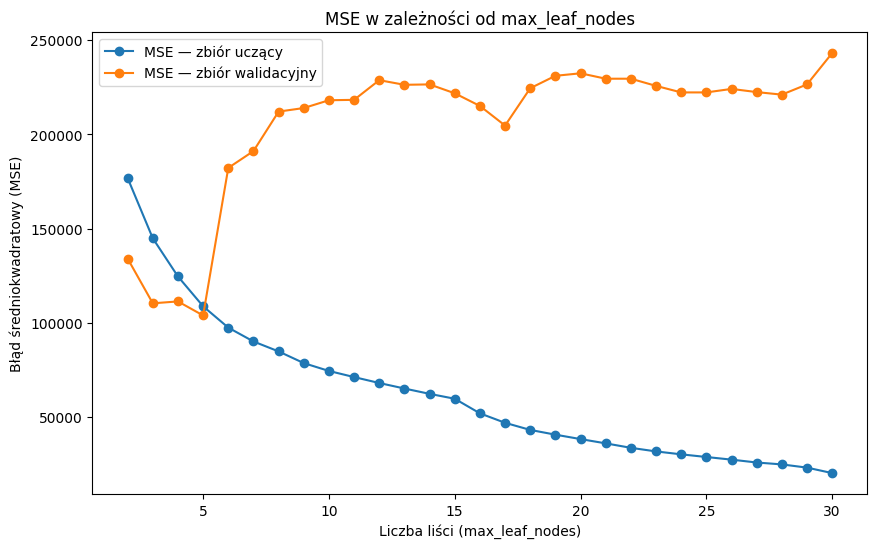

Wybrane max_leaf_nodes: 5
MSE na zbiorze testowym: 132578.92


In [6]:
from sklearn.metrics import mean_squared_error

mse_fit = []
mse_val = []
leaf_values = range(2, 31)

# Pętla, która będzie iterować przez różne wartości max_leaf_nodes (od 2 do 30)
for leaves in leaf_values:
    # Tworzenie modelu drzewa regresyjnego z aktualną maksymalną liczbą liści (i)
    model = tree.DecisionTreeRegressor(
        max_leaf_nodes=leaves, random_state=123
    )

    # Uczenie modelu na danych uczących
    model.fit(X_fit, y_fit)

    y_fit_pred = model.predict(X_fit) # Predykcje modelu dla danych uczących
    mse_fit.append(mean_squared_error(y_fit, y_fit_pred))

    y_val_pred = model.predict(X_val) # Predykcje modelu dla danych walidacyjnych
    mse_val.append(mean_squared_error(y_val, y_val_pred))

plt.figure(figsize=(10, 6))
plt.plot(leaf_values, mse_fit, label="MSE — zbiór uczący", marker="o")
plt.plot(leaf_values, mse_val, label="MSE — zbiór walidacyjny", marker="o")
plt.xlabel("Liczba liści (max_leaf_nodes)")
plt.ylabel("Błąd średniokwadratowy (MSE)")
plt.title("MSE w zależności od max_leaf_nodes")
plt.legend()
plt.show()

best_leaf_nodes = list(leaf_values)[np.argmin(mse_val)]
best_tree = tree.DecisionTreeRegressor(
    max_leaf_nodes=best_leaf_nodes, random_state=123
)
best_tree.fit(X_train, y_train)
test_mse = mean_squared_error(y_test, best_tree.predict(X_test))
print("Wybrane max_leaf_nodes:", best_leaf_nodes)
print(f"MSE na zbiorze testowym: {test_mse:.2f}")

### 1. Drzewa decyzyjne - klasyfikacja

In [7]:
# Wczytanie zbioru danych Pima Indians Diabetes, używanego do klasyfikacji (przewidywania cukrzycy)
pima = pd.read_csv("pima.csv")
# pima = pd.read_csv("link do raw GitHub")

Więcej o danych: https://www.openml.org/search?type=data&sort=runs&id=43483&status=active

In [8]:
pima.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [9]:
pima.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


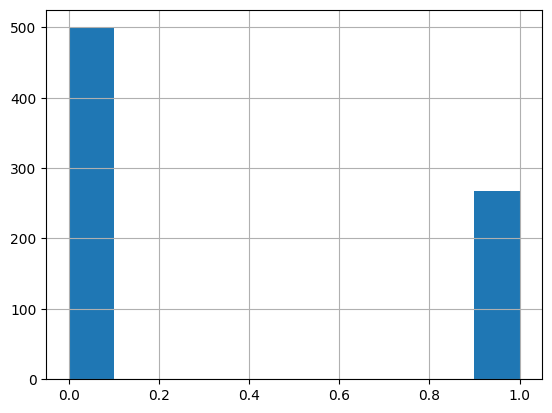

In [10]:
pima.Outcome.hist()
plt.show()

> Braki danych mogą być oznaczone jako 0!

### Kryterium podziału
a) wskaźnik błędu klasyfikacji (*classification error rate*) = udział obserwacji ze zbioru treningowego w danym regionie, które nie należą do przeważającej klasy.
    
$$E = 1 - max_{k}(\hat{p}_{mk}) $$
 
$\hat{p}_{mk}$ - proporcja obserwacji zbioru treningowego w m-tym regionie pochodząca z k-tej klasy
   
b) indeks Giniego   

 $$G = \sum_{k=1}^{K}\hat{p}_{mk}(1-\hat{p}_{mk})$$

 lub

 $$G = 1 - \sum_{k=1}^{K}\hat{p}_{mk}^2$$


Indeks Giniego przyjmuje małe wartości jeżeli $\hat{p}_{mk}$ jest bliski 0 lub 1. Z tego powodu indeks Giniego jest określany jako miara czystości węzła (*node purity*) - mała wartość wskazuje, że węzeł zawiera głównie obserwacje z jednej klasy.

c) entropia
 
 $$D = - \sum_{k=1}^{K}\hat{p}_{mk}log\hat{p}_{mk}$$

 $0 \leq \hat{p}_{mk} \leq 1 \ \rightarrow 0 \leq -\hat{p}_{mk}log\hat{p}_{mk}$

Podobnie jak indeks Giniego przyjmuje małe wartości (bliskie zero) gdy $\hat{p}_{mk}$ jest bliskie 0 lub 1.

### Przykład

Zbiór danych: 10 klientów, jedna zmienna *Czy klient posiada konto VIP? (Tak/Nie)*

Cel: chcemy przewidzieć *Czy kupią produkt (Tak/Nie)*

| Klient | Konto VIP| Kupił produkt |
| --- | --- | --- |
| 1 | Tak | Tak |
| 2 | Tak | Tak |
| 3 | Tak | Tak |
| 4 | Tak | Tak |
| 5 | Tak | Nie |
| 6 | Tak | Nie |
| 7 | Nie | Tak |
| 8 | Nie | Nie |
| 9 | Nie | Nie |
| 10 | Nie | Nie |

$Y$: **5 Tak**, **5 Nie** ($p_{\text{Tak}} = 0.5$, $p_{\text{Nie}} = 0.5$)

---

##### 1. Zanim dokonamy podziału, liczymy nieczystość całego zbioru:

1. **Entropia:** $- (0.5 \cdot \log_2 0.5 + 0.5 \cdot \log_2 0.5) = -(-0.5 - 0.5) =$ **1.0**

2. **Indeks Gini:** $1 - (0.5^2 + 0.5^2) = 1 - (0.25 + 0.25) =$ **0.5**

3. **Błąd klasyfikacji:** $1 - \max(0.5, 0.5) = 1 - 0.5 =$ **0.5**


##### 2. Podział na dwie gałęzie:

Gałąź A: Konto VIP = Tak (6 klientów)
$p_{\text{Tak}} = 4/6$, $p_{\text{Nie}} = 2/6$

**Entropia:** $-(\frac{4}{6}\log_2\frac{4}{6} + \frac{2}{6}\log_2\frac{2}{6}) \approx 0.918$

**Gini:** $1 - ((\frac{4}{6})^2 + (\frac{2}{6})^2) = 1 - (\frac{16}{36} + \frac{4}{36}) \approx 0.444$

**Błąd klasyfikacji:** $1 - \frac{4}{6} \approx 0.333$

---

Gałąź B: Konto VIP = Nie (4 klientów)
$p_{\text{Tak}} = 1/4$, $p_{\text{Nie}} = 3/4$

**Entropia:** $-(\frac{1}{4}\log_2\frac{1}{4} + \frac{3}{4}\log_2\frac{3}{4}) \approx 0.811$

**Gini:** $1 - ((0.25)^2 + (0.75)^2) = 1 - (0.0625 + 0.5625) = 0.375$

**Błąd klasyfikacji:** $1 - \frac{3}{4} = 0.25$


##### 3. Średnia ważona nieczystość po podziale

Aby ocenić jakość podziału, liczymy średnią ważoną (biorąc pod uwagę liczność gałęzi: $6/10 = 0.6$ dla Tak oraz $4/10 = 0.4$ dla Nie):

**Entropia po podziale:** $(0.6 \cdot 0.918) + (0.4 \cdot 0.811) = 0.551 + 0.324 =$ **0.875**

*Przyrost informacji (Information Gain):* $1.0 - 0.875 = \mathbf{0.125}$


**Gini po podziale:** $(0.6 \cdot 0.444) + (0.4 \cdot 0.375) = 0.266 + 0.150 =$ **0.416**

*Spadek Gini:* $0.5 - 0.416 = \mathbf{0.084}$


**Błąd klasyfikacji po podziale:** $(0.6 \cdot 0.333) + (0.4 \cdot 0.25) = 0.200 + 0.100 =$ **0.300**

*Redukcja błędu:* $0.5 - 0.3 = \mathbf{0.200}$




> Entropia opiera się na logarytmie i mocniej karze za rozkłady bliskie 50/50. Indeks Gini jest nieco prostszy obliczeniowo (oparty na kwadratach prawdopodobieństw) i preferowany w algorytmach typu CART ze względu na szybkość działania.

> Błąd klasyfikacji jest najmniej czuły na zmiany proporcji wewnątrz węzłów. Zauważ, że zmiana proporcji klas w gałęzi (np. z 50/50 na 60/40) zmieni wartość entropii i Gini, podczas gdy błąd klasyfikacji może pozostać na tym samym poziomie (bo liczy się tylko dominująca klasa). Z tego powodu w praktyce rzadko używa się błędu klasyfikacji jako kryteria podziału, choć świetnie nadaje się do końcowej oceny jakości gotowego modelu.

> Wszystkie trzy metryki w tym przykładzie wskazują, że podział według cechy "Konto VIP" redukuje nieczystość (zmniejsza entropię/Gini/błąd), co oznacza, że cecha ta niesie użyteczną informację predykcyjną.

> ### *Jak szukamy podziału gdy zmienna jest zmienną ciągłą?*

W przeciwieństwie do zmiennych kategorycznych (gdzie sprawdzamy kategorie typu Tak/Nie), przy zmiennej ciągłej algorytm musi sprawdzić wybrane progi podziału.

Wyobraźmy sobie, że próbujemy przewidzieć, czy klient kupi karnet na siłownię (Decyzja: Tak / Nie) na podstawie jego wieku.

|ID|Wiek|Decyzja|
|--|---|----|
|1|20|Nie|
|2|22|Nie|
|3|25|Tak|
|4|30|Tak|
|5|40|Tak|
|6|50|Nie|
---

Wartość entropi w początkowym węźle:
$p{Tak} = \frac{3}{6} = 0.5,$
$p_{Nie} = \frac{3}{6} = 0.5$
$$H = -0.5 \cdot \log_2(0.5) - 0.5 \cdot \log_2(0.5) = -0.5 \cdot (-1) - 0.5 \cdot (-1) = 1.0$$

##### Próg = 21.0

Lewa strona ($\le$ 21.0): 1 element (0 Tak, 1 Nie) $\rightarrow$ $H(L) = 0$

Prawa strona ($>$ 21.0): 5 elementów (3 Tak, 2 Nie) $\rightarrow$ $H(P) = -\frac{3}{5}\log_2(\frac{3}{5}) - \frac{2}{5}\log_2(\frac{2}{5}) \approx 0.971$

Entropia ważona: $(\frac{1}{6} \cdot 0) + (\frac{5}{6} \cdot 0.971) \approx \mathbf{0.809}$

---

###### Próg = 23.5 

Lewa strona ($\le$ 23.5): 2 elementy (0 Tak, 2 Nie) $\rightarrow$ $H(L) = 0$

Prawa strona ($>$ 23.5): 4 elementy (3 Tak, 1 Nie) $\rightarrow$ $H(P) = -\frac{3}{4}\log_2(\frac{3}{4}) - \frac{1}{4}\log_2(\frac{1}{4}) \approx 0.811$

Entropia ważona: $(\frac{2}{6} \cdot 0) + (\frac{4}{6} \cdot 0.811) \approx \mathbf{0.541}$

---

##### Próg = 27.5

Lewa strona ($\le$ 27.5): 3 elementy (1 Tak, 2 Nie) $\rightarrow$ $H(L) = -\frac{1}{3}\log_2(\frac{1}{3}) - \frac{2}{3}\log_2(\frac{2}{3}) \approx 0.918$

Prawa strona ($>$ 27.5): 3 elementy (2 Tak, 1 Nie) $\rightarrow$ $H(P) = -\frac{2}{3}\log_2(\frac{2}{3}) - \frac{1}{3}\log_2(\frac{1}{3}) \approx 0.918$

Entropia ważona: $(\frac{3}{6} \cdot 0.918) + (\frac{3}{6} \cdot 0.918) = \mathbf{0.918}$

---

##### Próg = 35.0

Lewa strona ($\le$ 35.0): 4 elementy (2 Tak, 2 Nie) $\rightarrow$ $H(L) = 1.0$

Prawa strona ($>$ 35.0): 2 elementy (1 Tak, 1 Nie) $\rightarrow$ $H(P) = 1.0$

Entropia ważona: $(\frac{4}{6} \cdot 1.0) + (\frac{2}{6} \cdot 1.0) = \mathbf{1.0}$ (brak redukcji entropii)

---

### Podsumowanie wyników

Algorytm testuje wszystkie progi i wybiera ten, który daje **najniższą entropię ważoną** lub **największy przyrost informacji**:

|Próg podziału|Entropia ważona|Przyrost Informacji (1.0−Entropia ważona)|
|--|--|--|
|21.0|$0.809$|$1.0 - 0.809 = \mathbf{0.191}$|
|23.5|$0.541$|$1.0 - 0.541 = \mathbf{0.459}$ 🏆 (Największa różnica)|
|27.5|$0.918$|$1.0 - 0.918 = \mathbf{0.082}$|
|35.0|$1.000$|$1.0 - 1.000 = \mathbf{0.000}$ (brak jakiejkolwiek zmiany)|


-----
##### *Zadanie 4*

Przygotuj zbiór danych `pima` do dalszej pracy. Podziel na zbiór zmiennych objaśniających i zmienną celu (utwórz zmienne `X` i `y`), a następnie podziel je na zbiór treningowy i testowy (`X_train`, `X_test`, `y_train` i `y_test`) w proporcji 7:3.

> Braki danych to nie zawsze wartości *NA* lub *NaN*.

In [11]:
# Podział na zmienne wejściowe i zmienną docelową
y = pima["Outcome"]
X = pima.drop(columns="Outcome")

# Stałe ziarno pozwala odtworzyć ten sam podział danych.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123
)


In [12]:
# Sprawdzenie rozmiaru zbiorów po podziale
print(f"Rozmiar zbioru treningowego X: {X_train.shape}")
print(f"Rozmiar zbioru testowego X: {X_test.shape}")

Rozmiar zbioru treningowego X: (537, 8)
Rozmiar zbioru testowego X: (231, 8)


-----
##### *Zadanie 5*

Zbuduj model drzewa dla danych z Zadania 4. Zapisz dopasowany model w zmiennej `Tree`.


In [13]:
from sklearn.tree import DecisionTreeClassifier

Tree = DecisionTreeClassifier(random_state=123)
Tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=123)

#### Pierwsza predykcja i ocena modelu

Po dopasowaniu modelu możemy obejrzeć strukturę drzewa, wyznaczyć predykcje modelu oraz policzyć dokładność (*accuracy*) na zbiorze testowym. To najbardziej intuicyjna miara dla klasyfikacji. Poniżej poznamy też miary oparte na macierzy pomyłek.


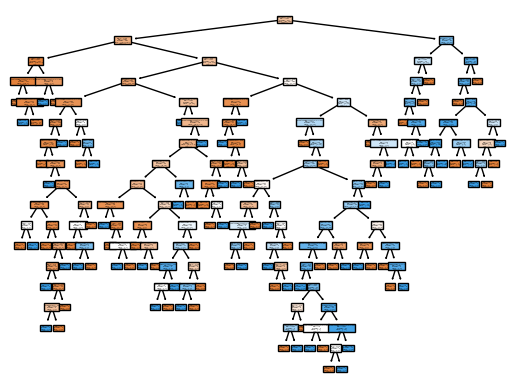

In [14]:
# Wizualizacja drzewa zbudowanego w Zadaniu 5
tree.plot_tree(
    Tree,
    feature_names=X_train.columns,
    class_names=[str(label) for label in Tree.classes_],
    filled=True,
)
plt.show()

In [15]:
# Predykcje dla 10 pierwszych obserwacji w zbiorze testowym
X_test_sample = X_test.iloc[:10]
X_test_sample

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
236,7,181,84,21,192,35.9,0.586,51
395,2,127,58,24,275,27.7,1.600,25
36,11,138,76,0,0,33.2,0.420,35
210,2,81,60,22,0,27.7,0.290,25
483,0,84,82,31,125,38.2,0.233,23
743,9,140,94,0,0,32.7,0.734,45
408,8,197,74,0,0,25.9,1.191,39
468,8,120,0,0,0,30.0,0.183,38
283,7,161,86,0,0,30.4,0.165,47
167,4,120,68,0,0,29.6,0.709,34


In [16]:
real_classes = y_test.iloc[:10]
predicted_classes = Tree.predict(X_test_sample)
predicted_probabilities = Tree.predict_proba(X_test_sample)

pd.DataFrame({
    "Real Class": real_classes,
    "Predicted Class": predicted_classes,
    "Predicted Probabilities": list(predicted_probabilities)
})

,Real Class,Predicted Class,Predicted Probabilities
236,1,1,"[0.0, 1.0]"
395,0,1,"[0.0, 1.0]"
36,0,1,"[0.0, 1.0]"
210,0,0,"[1.0, 0.0]"
483,0,0,"[1.0, 0.0]"
743,1,0,"[1.0, 0.0]"
408,1,1,"[0.0, 1.0]"
468,1,1,"[0.0, 1.0]"
283,1,1,"[0.0, 1.0]"
167,0,1,"[0.0, 1.0]"


In [17]:
# Dla klasyfikatora metoda score zwraca accuracy.
print(f"Accuracy na zbiorze testowym: {Tree.score(X_test, y_test):.3f}")

Accuracy na zbiorze testowym: 0.684


#### Macierz pomyłek i metryki klasyfikacji

W zadaniu klasyfikacji nie wystarczy wiedzieć, ile predykcji było poprawnych. Macierz pomyłek zestawia klasy rzeczywiste z klasami przewidzianymi przez model.

- **True Positive (TP):** model przewidział klasę pozytywną i była to prawda;
- **True Negative (TN):** model przewidział klasę negatywną i była to prawda;
- **False Positive (FP):** model przewidział klasę pozytywną, ale była to pomyłka („fałszywy alarm”);
- **False Negative (FN):** model przewidział klasę negatywną, ale była to pomyłka („przeoczenie”).

<img src="confusion_matrix.png" width="400"/>

Na podstawie macierzy pomyłek obliczamy między innymi:

- **Dokładność (accuracy):** odsetek wszystkich poprawnych predykcji,
  $$\mathrm{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}.$$
- **Czułość (recall):** odsetek rzeczywistych pozytywów poprawnie rozpoznanych przez model,
  $$\mathrm{Recall} = \frac{TP}{TP + FN}.$$
- **Precyzję (precision):** odsetek trafnych predykcji pozytywnych,
  $$\mathrm{Precision} = \frac{TP}{TP + FP}.$$
- **Miarę F1:** średnią harmoniczną precyzji i czułości,
  $$\mathrm{F1} = 2 \cdot \frac{\mathrm{Precision} \cdot \mathrm{Recall}}{\mathrm{Precision} + \mathrm{Recall}}.$$


-----
##### *Zadanie 6*

Wyznacz macierz pomyłek oraz miary `accuracy`, `precision`, `recall` i `f1` dla predykcji drzewa z Zadania 5. Porównaj macierz pomyłek dla zbioru testowego z macierzą dla zbioru treningowego.


In [18]:
print("Macierz pomyłek dla zbioru testowego:")
print(confusion_matrix(y_test, Tree.predict(X_test)))


Macierz pomyłek dla zbioru testowego:
[[103  40]
 [ 33  55]]


In [19]:
y_pred = Tree.predict(X_test)
print("Metryki dla zbioru testowego:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred):.3f}")
print(f"F1:        {f1_score(y_test, y_pred):.3f}")


Metryki dla zbioru testowego:
Accuracy:  0.684
Precision: 0.579
Recall:    0.625
F1:        0.601


In [20]:
print("Macierz pomyłek dla zbioru treningowego:")
print(confusion_matrix(y_train, Tree.predict(X_train)))


Macierz pomyłek dla zbioru treningowego:
[[357   0]
 [  0 180]]
